# 04 Results

This notebook shows how well each model works, tests our three hypotheses and looks at which users get bad recommendations. It only reads the scores saved by `03_models.ipynb`, so it trains no models and runs in seconds.

**How we measure.** Each model gives every test user a top 10 list of beers. We compare the list with the beers the user actually rated later: the hidden ratings from the split in `02_split.ipynb`. That is the answer key. More hits near the top = better score.

**Baseline is not the answer key.** It is the simplest model: it recommends the most popular beers to everyone. It is scored against the answer key like the other models. The other models have to beat it to be useful.

All final numbers are for the 90 test users.

1. The models and metrics
2. Main results
3. Validation vs. test
4. Hypotheses
5. Robustness: only beers the user liked
6. Why the numbers are low
7. Failure analysis
8. Summary

In [1]:
import os
from pathlib import Path

# Run from the project folder so `src` can be imported
if Path.cwd().name == "notebooks":
    os.chdir("..")

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import wilcoxon

from src.data import load_beers
from src.split import load_split

METRICS = ["recall@10", "ndcg@10", "coverage@10"]
RUNS = ["baseline", "A", "B", "C", "D", "E"]
RUN_LABELS = {
    "baseline": "Baseline: most popular",
    "A": "A: most popular + home bonus",
    "B": "B: BPR, all countries",
    "C": "C: BPR + home bonus",
    "D": "D: BPR, Nordic only",
    "E": "E: BPR, non-Nordic sample",
}
ALPHA = 0.05

# Fixed colour per run, so a run has the same colour in every figure
RUN_COLORS = {"baseline": "#2a78d6", "A": "#8ab8ec", "B": "#eb6834", "C": "#1baf7a", "D": "#4a3aa7", "E": "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e5e5", "axes.axisbelow": True})

# Both files are made by 03_models.ipynb
all_results = pd.read_csv("results/model_results.csv")
all_user_results = pd.read_csv("results/user_scores.csv")
# 'all' = every hidden beer counts as a hit. 'liked' (rated 3.5 or higher) is only used in section 5
results = all_results[all_results["answer_key"] == "all"]
user_results = all_user_results[all_user_results["answer_key"] == "all"]
test_scores = user_results[user_results["group"] == "test"]
ndcg = test_scores.pivot(index="user_id", columns="run", values="ndcg")[RUNS]
recall = test_scores.pivot(index="user_id", columns="run", values="recall")[RUNS]

## 1. The models and metrics

| Run | Model | Trained on | Used for |
|---|---|---|---|
| Baseline | Most popular beers | All countries except Norway | Comparison point |
| A | Most popular beers + bonus for Norwegian beers | Same as baseline | Explains C (section 4) |
| B | BPR | All countries except Norway | H1 |
| C | BPR + bonus for Norwegian beers | Same as B | H2 |
| D | BPR | Only Sweden, Denmark and Finland | H3 |
| E | BPR | Random countries outside the Nordics, same amount of data as D | H3 |

All BPR models also see the first 5 ratings of each Norwegian user. No model recommends a beer the user has already rated. Model size and bonus were picked on validation users (A uses the same bonus as C) in `03_models.ipynb`.

| Metric | What it means | How to read it |
|---|---|---|
| Recall@10 | Share of the user's hidden beers that are in the top 10 | Higher is better |
| NDCG@10 | Like recall, but a hit at the top of the list counts more than a hit further down | 0 = no hits, 1 = perfect. **Our main metric** |
| Coverage@10 | Share of all beers that are recommended to at least one user | Higher = more variety. Says nothing about quality |

## 2. Main results

Test users only. Higher is better. The best value in each column is highlighted.

In [3]:
test_results = results[results["group"] == "test"].set_index("run").loc[RUNS, METRICS]
test_results.to_csv("results/test_results.csv")

test_results.rename(index=RUN_LABELS).style \
    .format({"recall@10": "{:.4f}", "ndcg@10": "{:.3f}", "coverage@10": "{:.5f}"}) \
    .highlight_max(color="#d6e6f9")

,recall@10,ndcg@10,coverage@10
run,,,
Baseline: most popular,0.0125,0.332,0.00003
A: most popular + home bonus,0.0171,0.310,0.00003
"B: BPR, all countries",0.0100,0.251,0.00122
C: BPR + home bonus,0.0206,0.360,0.00047
"D: BPR, Nordic only",0.0091,0.282,0.00050
"E: BPR, non-Nordic sample",0.0069,0.174,0.00125


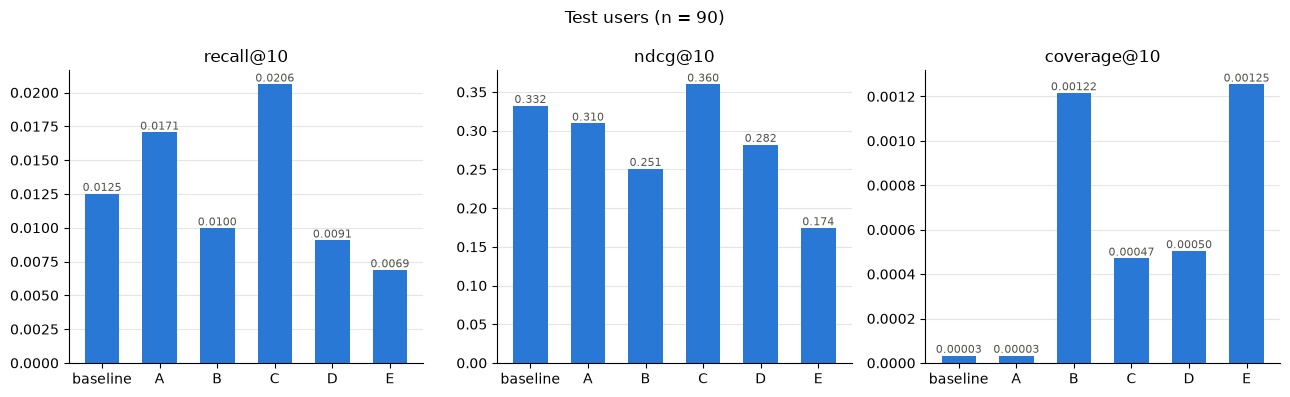

In [4]:
LABEL_FORMATS = {"recall@10": "%.4f", "ndcg@10": "%.3f", "coverage@10": "%.5f"}

fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 4))
for ax, metric in zip(axes, METRICS):
    values = test_results[metric]
    bars = ax.bar(values.index, values, color=RUN_COLORS["baseline"], width=0.6)
    ax.bar_label(bars, fmt=LABEL_FORMATS[metric], fontsize=8, color="#52514e")
    ax.set_title(metric)
    ax.grid(axis="x", visible=False)
fig.suptitle("Test users (n = 90)")
fig.tight_layout()
fig.savefig("results/metrics_by_run.png", dpi=150)

## 3. Validation vs. test

The same models scored on both user groups (NDCG@10). If a number changes a lot between the groups, the result is not very stable. With only 90 users in each group, some change is normal.

In [5]:
ndcg_by_group = results.pivot(index="run", columns="group", values="ndcg@10").loc[RUNS, ["validation", "test"]]
ndcg_by_group["difference"] = ndcg_by_group["test"] - ndcg_by_group["validation"]
ndcg_by_group.rename(index=RUN_LABELS).round(3)

group,validation,test,difference
run,,,
Baseline: most popular,0.287,0.332,0.046
A: most popular + home bonus,0.307,0.310,0.003
"B: BPR, all countries",0.305,0.251,-0.054
C: BPR + home bonus,0.385,0.360,-0.025
"D: BPR, Nordic only",0.275,0.282,0.007
"E: BPR, non-Nordic sample",0.207,0.174,-0.033


## 4. Hypotheses

Each hypothesis compares two models on the same 90 test users. A Wilcoxon test checks if the difference is too big to be chance. If p < 0.05, we say it is not chance.

- **Supported:** the new model is better, and it is not chance
- **Not significant:** the difference may be chance
- **Rejected:** the new model is worse, and it is not chance

"Users better" and "users worse" count how many of the 90 users get a higher or lower score with the new model.

In [6]:
HYPOTHESES = [
    ("H1", "Does BPR on foreign data beat the popular list?", "baseline", "B"),
    ("H2", "Does a home-country bonus help?", "B", "C"),
    ("H3", "Is Nordic data better than the same amount of non-Nordic data?", "E", "D"),
]


def verdict(change, p_value):
    """Plain-language outcome of a hypothesis test."""
    if p_value >= ALPHA:
        return "Not significant"
    return "Supported" if change > 0 else "Rejected"


def compare(comparisons, index_name, ndcg=ndcg, recall=recall):
    """One row per (name, question, reference, run): change in NDCG/recall, users better/worse and p-value."""
    rows = []
    for name, question, reference, run in comparisons:
        difference = ndcg[run] - ndcg[reference]
        p_value = wilcoxon(ndcg[run], ndcg[reference]).pvalue
        rows.append({
            index_name: name,
            "question": question,
            "comparison": f"{run} vs {reference}",
            "ndcg before": ndcg[reference].mean(),
            "ndcg after": ndcg[run].mean(),
            "ndcg change": ndcg[run].mean() / ndcg[reference].mean() - 1,
            "recall change": recall[run].mean() / recall[reference].mean() - 1,
            "users better": (difference > 0).sum(),
            "users worse": (difference < 0).sum(),
            "p-value": p_value,
            "result": verdict(difference.mean(), p_value),
        })
    return pd.DataFrame(rows).set_index(index_name)


TABLE_FORMAT = {
    "ndcg before": "{:.3f}", "ndcg after": "{:.3f}", "ndcg change": "{:+.1%}",
    "recall change": "{:+.1%}", "p-value": "{:.3f}",
}

hypothesis_table = compare(HYPOTHESES, "hypothesis")
hypothesis_table.to_csv("results/hypothesis_tests.csv")
hypothesis_table.style.format(TABLE_FORMAT)

,question,comparison,ndcg before,ndcg after,ndcg change,recall change,users better,users worse,p-value,result
hypothesis,,,,,,,,,,
H1,Does BPR on foreign data beat the popular list?,B vs baseline,0.332,0.251,-24.4%,-20.4%,23,43,0.003,Rejected
H2,Does a home-country bonus help?,C vs B,0.251,0.360,+43.4%,+106.7%,57,13,0.000,Supported
H3,Is Nordic data better than the same amount of non-Nordic data?,D vs E,0.174,0.282,+61.8%,+31.9%,46,17,0.000,Supported


### Why is C better than the baseline?

B alone loses to the baseline, but C beats it. Is that the bonus or BPR? Run A gives the popular list the same bonus as C. Then each step changes one thing:

- **Baseline → A:** only the bonus is added
- **A → C:** the popular list is replaced by BPR, with the same bonus
- **Baseline → C:** both changes together

Beer country comes from the brewery. Some beers from foreign brands are brewed in Norway (for example Mikkeller at Lervig), so they count as Norwegian.

In [7]:
BONUS_STEPS = [
    ("Baseline → A", "Does the bonus help the popular list?", "baseline", "A"),
    ("A → C", "Does BPR help when the bonus is used?", "A", "C"),
    ("Baseline → C", "Does C beat the popular list?", "baseline", "C"),
]
bonus_table = compare(BONUS_STEPS, "step")
bonus_table.to_csv("results/bonus_steps.csv")
bonus_table.style.format(TABLE_FORMAT)

,question,comparison,ndcg before,ndcg after,ndcg change,recall change,users better,users worse,p-value,result
step,,,,,,,,,,
Baseline → A,Does the bonus help the popular list?,A vs baseline,0.332,0.310,-6.9%,+36.2%,26,44,0.254,Not significant
A → C,Does BPR help when the bonus is used?,C vs A,0.310,0.360,+16.3%,+20.8%,46,25,0.004,Supported
Baseline → C,Does C beat the popular list?,C vs baseline,0.332,0.360,+8.3%,+64.5%,40,27,0.079,Not significant


## 5. Robustness: only beers the user liked

So far, every hidden beer counts as a hit, even one the user rated 0.5 out of 5. Then we measure which beers the user will drink, not which beers they will like. Here we only count hidden beers rated **3.5 or higher** (about a third of them) and run the same tests again. Models and settings are the same; only the answer key changes. If the results hold, they do not just come from beers people drank but did not like.

In [8]:
liked_scores = all_user_results[(all_user_results["answer_key"] == "liked") & (all_user_results["group"] == "test")]
liked_ndcg = liked_scores.pivot(index="user_id", columns="run", values="ndcg")[RUNS]
liked_recall = liked_scores.pivot(index="user_id", columns="run", values="recall")[RUNS]

hidden_test = load_split()[2].query("group == 'test'")
liked_test = hidden_test[hidden_test["rating"] >= 3.5]
print(f"{len(liked_test) / len(hidden_test):.0%} of hidden beers are liked, for {liked_test['user_id'].nunique()} of 90 users")
print(f"Share of Norwegian beers: {(hidden_test['beer_country'] == 'Norway').mean():.0%} of all hidden, "
      f"{(liked_test['beer_country'] == 'Norway').mean():.0%} of liked")

pd.DataFrame({"all": ndcg.mean(), "liked": liked_ndcg.mean()}).rename(index=RUN_LABELS).round(3)

35% of hidden beers are liked, for 90 of 90 users
Share of Norwegian beers: 29% of all hidden, 28% of liked


,all,liked
run,,
Baseline: most popular,0.332,0.265
A: most popular + home bonus,0.310,0.287
"B: BPR, all countries",0.251,0.152
C: BPR + home bonus,0.360,0.238
"D: BPR, Nordic only",0.282,0.211
"E: BPR, non-Nordic sample",0.174,0.092


In [9]:
liked_table = compare(HYPOTHESES + BONUS_STEPS, "comparison name", ndcg=liked_ndcg, recall=liked_recall)
liked_table.to_csv("results/liked_tests.csv")
liked_table.style.format(TABLE_FORMAT)

,question,comparison,ndcg before,ndcg after,ndcg change,recall change,users better,users worse,p-value,result
comparison name,,,,,,,,,,
H1,Does BPR on foreign data beat the popular list?,B vs baseline,0.265,0.152,-42.5%,-23.7%,22,41,0.000,Rejected
H2,Does a home-country bonus help?,C vs B,0.152,0.238,+56.3%,+80.4%,48,11,0.000,Supported
H3,Is Nordic data better than the same amount of non-Nordic data?,D vs E,0.092,0.211,+129.3%,+71.5%,49,12,0.000,Supported
Baseline → A,Does the bonus help the popular list?,A vs baseline,0.265,0.287,+8.2%,+39.4%,39,31,0.419,Not significant
A → C,Does BPR help when the bonus is used?,C vs A,0.287,0.238,-17.0%,-1.2%,28,39,0.054,Not significant
Baseline → C,Does C beat the popular list?,C vs baseline,0.265,0.238,-10.2%,+37.7%,33,37,0.572,Not significant


## 6. Why the numbers are low

Recall@10 is very low for all models. This is expected: most users have many hidden beers, but we only recommend 10. If a user has 115 hidden beers, even a perfect list finds at most 10 / 115 ≈ 9 % of them.

Some hidden beers are also missing from the training data, so no model can recommend them.

In [10]:
train, history, hidden = load_split()
test_hidden = hidden[hidden["group"] == "test"]
train_beers = set(train["beer_id"])

hidden_by_user = test_hidden.groupby("user_id")
n_hidden = hidden_by_user.size()
max_recall = (10 / n_hidden).clip(upper=1)
share_unreachable = hidden_by_user["beer_id"].apply(lambda beers: (~beers.isin(train_beers)).mean())

pd.DataFrame({
    "median": [n_hidden.median(), max_recall.median(), share_unreachable.median()],
    "mean": [n_hidden.mean(), max_recall.mean(), share_unreachable.mean()],
}, index=["hidden beers per user", "best possible recall@10", "share of hidden beers not in train"]).round(3)

,median,mean
hidden beers per user,115.000,956.011
best possible recall@10,0.087,0.235
share of hidden beers not in train,0.017,0.044


## 7. Failure analysis

Which users get bad recommendations, and why? We describe each test user (number of ratings, how much Norwegian beer they drink, favourite style) and look at their score for each model. All scores are still measured against the hidden ratings.

The tables show all six models. The first figure shows the models trained on all data (baseline, A, B, C). The second figure compares D and E.

We only use the hidden ratings to describe users here, never for training.

In [11]:
styles = load_beers().set_index("beer_id")["style"]
test_ratings = pd.concat([history[history["group"] == "test"], test_hidden])

users = pd.DataFrame({
    "n_ratings": test_ratings.groupby("user_id").size(),
    "share_norwegian": hidden_by_user["beer_country"].apply(lambda country: (country == "Norway").mean()),
    "share_unreachable": share_unreachable,
    "top_style": test_ratings["beer_id"].map(styles).groupby(test_ratings["user_id"]).agg(lambda style: style.mode().iloc[0]),
})
users = users.join(ndcg.add_suffix("_ndcg"))
users.describe().round(3)

,n_ratings,share_norwegian,share_unreachable,baseline_ndcg,A_ndcg,B_ndcg,C_ndcg,D_ndcg,E_ndcg
count,90.000,90.000,90.000,90.000,90.000,90.000,90.000,90.000,90.000
mean,961.011,0.392,0.044,0.332,0.310,0.251,0.360,0.282,0.174
std,1976.632,0.174,0.091,0.374,0.322,0.305,0.357,0.337,0.258
min,15.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,30.000,0.279,0.000,0.000,0.000,0.000,0.065,0.000,0.000
50%,120.000,0.381,0.017,0.159,0.221,0.095,0.221,0.110,0.066
75%,755.000,0.489,0.053,0.673,0.532,0.464,0.705,0.477,0.256
max,10483.000,0.900,0.769,1.000,1.000,0.927,1.000,1.000,1.000


### Users with no hits

Some users get no hits at all from our best model (C). How are they different from the rest?

In [12]:
no_hits = (users["C_ndcg"] == 0).map({True: "no hits", False: "at least one hit"}).rename("C result")
print(f"{(users['C_ndcg'] == 0).mean():.0%} of test users get no hits from run C")
no_hit_table = users.groupby(no_hits)[["n_ratings", "share_norwegian", "share_unreachable"]].median()
no_hit_table.insert(0, "users", no_hits.value_counts())
no_hit_table.round(3)

24% of test users get no hits from run C


,users,n_ratings,share_norwegian,share_unreachable
C result,,,,
at least one hit,68,341.5,0.393,0.021
no hits,22,26.0,0.276,0.000


### Score by number of ratings and taste for Norwegian beer

We split the users into four equal groups (about 22 users each): from fewest to most ratings, and from least to most Norwegian beer.

In [13]:
QUARTILES = ["low", "mid-low", "mid-high", "high"]
# rank first so ties do not break the four equal groups
users["activity"] = pd.qcut(users["n_ratings"].rank(method="first"), 4, labels=QUARTILES)
users["norwegian_taste"] = pd.qcut(users["share_norwegian"].rank(method="first"), 4, labels=QUARTILES)

GROUPINGS = {"activity": "Number of ratings", "norwegian_taste": "Share of Norwegian beers"}
group_tables = {
    column: users.groupby(column, observed=True)[[f"{run}_ndcg" for run in RUNS]].mean().set_axis(RUNS, axis=1)
    for column in GROUPINGS
}
pd.concat(group_tables, names=["grouping", "quartile"]).rename(columns=RUN_LABELS).round(3)

Baseline: most popular  \
grouping        quartile                           
activity        low                        0.019   
                mid-low                    0.130   
                mid-high                   0.456   
                high                       0.722   
norwegian_taste low                        0.227   
                mid-low                    0.597   
                mid-high                   0.352   
                high                       0.166   

                          A: most popular + home bonus  B: BPR, all countries  \
grouping        quartile                                                        
activity        low                              0.056                  0.022   
                mid-low                          0.116                  0.063   
                mid-high                         0.349                  0.301   
                high                             0.711                  0.612   
norwegian_taste low                              0.182                  0.198   
                mid-low                          0.514                  0.402   
                mid-high                         0.354                  0.275   
                high                             0.199                  0.137   

                          C: BPR + home bonus  D: BPR, Nordic only  \
grouping        quartile                                             
activity        low                     0.062                0.010   
                mid-low                 0.145                0.073   
                mid-high                0.478                0.305   
                high                    0.751                0.731   
norwegian_taste low                     0.192                0.257   
                mid-low                 0.577                0.452   
                mid-high                0.408                0.317   
                high                    0.274                0.112   

                          E: BPR, non-Nordic sample  
grouping        quartile                             
activity        low                           0.020  
                mid-low                       0.045  
                mid-high                      0.147  
                high                          0.478  
norwegian_taste low                           0.153  
                mid-low                       0.306  
                mid-high                      0.187  
                high                          0.058

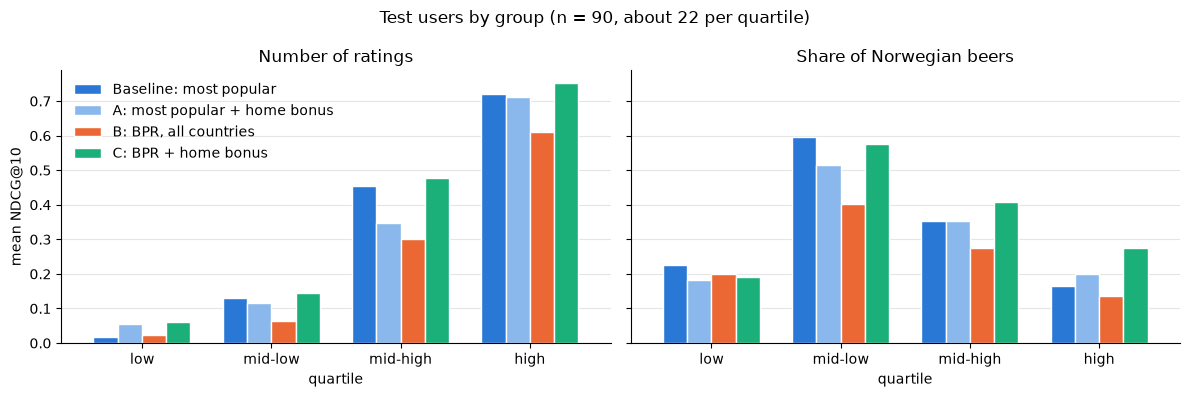

In [14]:
def plot_groups(runs, title, file_name):
    """Bar chart of mean NDCG@10 per quartile for the given runs, saved to results/."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, (column, grouping) in zip(axes, GROUPINGS.items()):
        group_tables[column][runs].rename(columns=RUN_LABELS).plot.bar(
            ax=ax, rot=0, color=[RUN_COLORS[run] for run in runs], width=0.75, edgecolor="white", linewidth=1)
        ax.set_title(grouping)
        ax.set_xlabel("quartile")
        ax.set_ylabel("mean NDCG@10")
        ax.grid(axis="x", visible=False)
    axes[1].get_legend().remove()
    axes[0].legend(frameon=False)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(f"results/{file_name}", dpi=150)


plot_groups(["baseline", "A", "B", "C"], "Test users by group (n = 90, about 22 per quartile)", "failure_analysis.png")

### D vs. E: who gains from Nordic data?

The same groups, but for D and E. If Nordic data works because Nordic taste is close to Norwegian taste, D should help most for users who drink a lot of Norwegian beer.

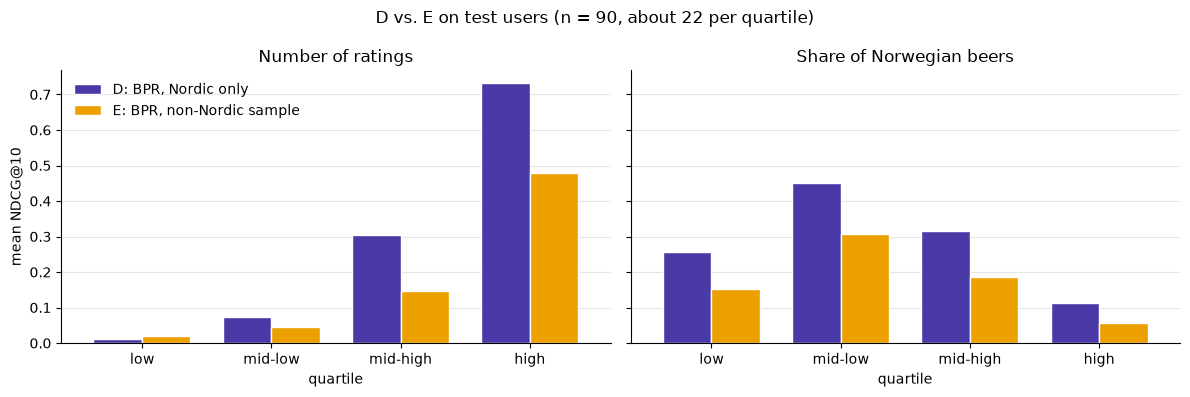

In [15]:
plot_groups(["D", "E"], "D vs. E on test users (n = 90, about 22 per quartile)", "failure_analysis_d_vs_e.png")

### Score by favourite beer style

Only styles that are the favourite of at least 3 test users.

In [16]:
style_table = users.groupby("top_style").agg(users=("C_ndcg", "size"), **{
    f"{run}_ndcg": (f"{run}_ndcg", "mean") for run in RUNS
})
style_table[style_table["users"] >= 3].sort_values("C_ndcg").round(3)

,users,baseline_ndcg,A_ndcg,B_ndcg,C_ndcg,D_ndcg,E_ndcg
top_style,,,,,,,
Brown Ale,3,0.000,0.049,0.000,0.075,0.000,0.000
Belgian Strong Ale,5,0.250,0.105,0.045,0.075,0.030,0.042
American Pale Ale,7,0.033,0.104,0.072,0.141,0.097,0.000
Imperial IPA,3,0.197,0.161,0.129,0.235,0.195,0.137
Imperial Stout,10,0.269,0.315,0.110,0.261,0.124,0.080
Pale Lager,12,0.292,0.236,0.301,0.400,0.216,0.216
India Pale Ale (IPA),36,0.570,0.526,0.453,0.590,0.539,0.314


## 8. Summary

| | Result | In short |
|---|---|---|
| **H1** | Rejected | Plain BPR (B) does **worse** than the popular list: NDCG 0.25 vs. 0.33. It is worse for 43 users and better for 23. |
| **H2** | Supported | The bonus for Norwegian beers (C) gives NDCG +43 % over B. Better for 57 users, worse for 13. |
| **H3** | Supported | With the same amount of data, Nordic data (D) beats non-Nordic data (E): NDCG +62 %. |

**C vs. the popular lists (run A)**
- C has the highest NDCG (0.36), but it is **not significantly better** than the baseline (0.33, p = 0.08).
- The bonus alone does not help the popular list: A is not better than the baseline (0.31 vs. 0.33, not significant).
- C beats A (+16 %, p = 0.004). With the bonus, BPR does better than the popular list.

**Robustness: only beers the user liked (section 5)**
- H1, H2 and H3 give the same result when only beers rated 3.5 or higher count as hits.
- But C is no longer the best model. A (0.29) and the baseline (0.26) are ahead of C (0.24). The differences between them are not significant.
- So BPR is good at finding beers the user will **drink**, but not better than the popular list at finding beers they will **like**. Popular beers are popular because many people like them.
- Norwegian beers are 29 % of all hidden beers and 28 % of liked ones. Norwegians drink a lot of Norwegian beer, but do not like it more than other beer.

**Answers to the research questions**
- **RQ1:** Partly. A popular list from other countries is hard to beat. Plain BPR is worse, and our best model (C) is only slightly better, not significantly. For beers the user liked, the popular list is as good as or better than C.
- **RQ2:** Yes, when it is added to BPR (H2). Added to the popular list (A), it does not help.
- **RQ3:** Yes. Data from similar countries (H3) helps more than the same amount of data from other countries. This also holds for liked beers.

**Failure analysis**
- Users with few ratings get the worst results. Users with no hits from C have a median of 26 ratings, the rest 342. Part of this is the metric: with few hidden beers there are fewer chances to hit.
- The Norwegian bonus helps most for users who drink a lot of Norwegian beer (0.14 → 0.27). For users who drink little Norwegian beer it does not help.
- D beats E about equally in all groups, also for users who drink little Norwegian beer. So Nordic data seems to help in general, not only for local taste.
- Fans of IPA and pale lager get the best results. Fans of Belgian ales, brown ales and stouts get the worst (small groups, 3–10 users).

**Keep in mind**
- Only 90 test users. B was a bit better than the baseline on validation users, but worse on test users.
- The best bonus (w = 1.0) and model size (128) were the largest we tried. Larger values might work even better.
- D has fewer users with more ratings each than E. This may explain part of the difference, not only culture.
- The bonus makes the lists less varied: C has lower coverage than B.
- Beer country comes from the brewery. Half of A's top 10 are Mikkeller beers brewed at Lervig in Norway, so they count as Norwegian.